初始化，导入程序包与检测

In [150]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jax import lax
import sys
import time
import numpy as np
from functools import partial

jax.config.update("jax_enable_x64", True)

print("Python:", sys.version.split()[0])
print("JAX:", jax.__version__)
print("Devices:", jax.devices())
print("浮点类型:", jnp.asarray(1.0).dtype)

Python: 3.12.16
JAX: 0.12.0.1
Devices: [CpuDevice(id=0)]
浮点类型: float64


选择二维扩散方程作为第一步学习的内容，同时学习粘性部分算子的编写方法

$$
\frac{\partial u}{\partial t}
=
\nu \nabla^2 u
$$
在二维的情况下：
$$
\frac{\partial u}{\partial t}
=
\nu\left(
\frac{\partial^2u}{\partial x^2}
+
\frac{\partial^2u}{\partial y^2}
\right)
$$

边界条件
$$
\begin{aligned}
\Omega &= [0,1]\times[0,1],\\
u(x,y,0) &= \sin(\pi x)\sin(\pi y),\\
u|_{\partial\Omega} &= 0.
\end{aligned}
$$

推导过程与离散方法

二阶中心差分

$$
x_i=i\Delta x,\qquad y_j=j\Delta y
$$

$$
\Delta x=\frac{L_x}{N_x-1},
\qquad
\Delta y=\frac{L_y}{N_y-1}
$$
$$
\frac{\partial^2 u}{\partial x^2}
\approx
\frac{
    u_{i+1,j}-2u_{i,j}+u_{i-1,j}
}{
    \Delta x^2
}
$$

将x和y方向的离散结合，得到五点差分格式：
$$
\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}
\approx
\frac{u_{i+1,j}-2u_{i,j}+u_{i-1,j}}{\Delta x^2}
+
\frac{u_{i,j+1}-2u_{i,j}+u_{i,j-1}}{\Delta y^2}
$$

In [151]:
def laplacian(u, dx, dy):
    center = u[1:-1, 1:-1]

    d2x = (
        u[2:, 1:-1]
        - 2.0 * center
        + u[:-2, 1:-1]
    ) / dx**2

    d2y = (
        u[1:-1, 2:]
        - 2.0 * center
        + u[1:-1, :-2]
    ) / dy**2

    return jnp.zeros_like(u).at[1:-1, 1:-1].set(d2x + d2y)

测试

In [152]:
lap_num = laplacian(u0, dx, dy)
lap_exact = -2 * jnp.pi**2 * u0
lap_error = float(jnp.max(jnp.abs(lap_num[1:-1,1:-1] - lap_exact[1:-1,1:-1])))
print(f"离散 Laplace 的最大内点误差: {lap_error:.6e}")

离散 Laplace 的最大内点误差: 3.963268e-03


时间离散采用显式欧拉方法：
$$
\boxed{
u_{i,j}^{n+1}
=
u_{i,j}^n
+
\nu\Delta t(\nabla_h^2 u^n)_{i,j}
}
$$

以下设置时间循环函数

In [153]:

def step(u, dt, dx, dy, nu):
    u_next = u + nu * dt * laplacian(u, dx, dy)

    # 四条边的零 Dirichlet 边界条件
    return (
        u_next.at[0, :].set(0.0)
              .at[-1, :].set(0.0)
              .at[:, 0].set(0.0)
              .at[:, -1].set(0.0)
    )


时间步长限制
$$
\Delta t \leq \frac{1}{2\nu}\left(\frac{1}{\Delta x^2}+\frac{1}{\Delta y^2}\right)^{-1}
$$

In [154]:
dt_max = 0.5 / (nu * (1.0 / dx**2 + 1.0 / dy**2))
safety = 0.8
nsteps = int(np.ceil(t_end / (safety * dt_max)))
dt = t_end / nsteps

print(f"稳定上限 dt_max = {dt_max:.8f}")
print(f"实际 dt = {dt:.8f}, 时间步数 = {nsteps}")
assert dt <= dt_max, "显式扩散格式不满足稳定性条件"

稳定上限 dt_max = 0.00122070
实际 dt = 0.00097561, 时间步数 = 205


In [155]:

@partial(jax.jit, static_argnames=("nsteps",))
def evolve(u0, dt, dx, dy, nu, nsteps):
    return lax.fori_loop(
        0,
        nsteps,
        lambda i, u: step(u, dt, dx, dy, nu),
        u0
    )


网格化与初始化

In [156]:
nx = ny = 65
Lx = Ly = 1.0
nu= 0.05
t_end = 0.2
x = jnp.linspace(0.0, Lx, nx)
y = jnp.linspace(0.0, Ly, ny)
dx = Lx / (nx - 1)
dy = Ly / (ny - 1)

X, Y = jnp.meshgrid(x, y, indexing="ij")
u0 = jnp.sin(jnp.pi * X) * jnp.sin(jnp.pi * Y)

print("形状", u0.shape, "dx =", dx, "dy =", dy)
print("边界最大绝对值:", float(jnp.max(jnp.abs(u0[0, :]))))

形状 (65, 65) dx = 0.015625 dy = 0.015625
边界最大绝对值: 0.0


初始状态可视化

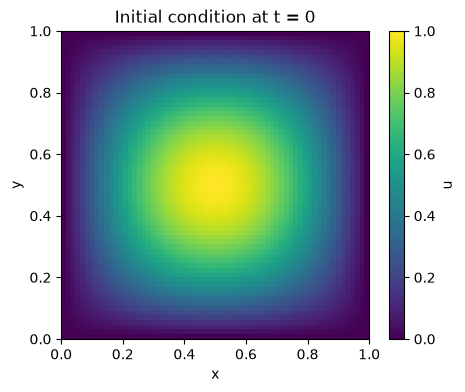

In [157]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(np.asarray(u0).T, origin="lower", extent=(0, Lx, 0, Ly), cmap="viridis")
ax.set(xlabel="x", ylabel="y", title="Initial condition at t = 0")
fig.colorbar(im, ax=ax, label="u")
plt.show()

调用和计算

In [158]:
# 首次调用会包含 JIT 编译时间。
t0 = time.perf_counter()
u_num = evolve(u0, dt, dx, dy, nu, nsteps)
u_num.block_until_ready()
first_call = time.perf_counter() - t0

# 第二次调用可用于粗略感受编译缓存效果。
t0 = time.perf_counter()
u_again = evolve(u0, dt, dx, dy, nu, nsteps)
u_again.block_until_ready()
second_call = time.perf_counter() - t0

print(f"首次调用（含编译）: {first_call:.4f} s")
print(f"第二次调用（不含首次编译）: {second_call:.4f} s")
print("最终最大值:", float(u_num.max()))

首次调用（含编译）: 0.0444 s
第二次调用（不含首次编译）: 0.0009 s
最终最大值: 0.8208232233115351


解析解与误差验证

对本课选择的初始/边界条件，可以用分离变量法得到：

$$
\boxed{u_{\mathrm{exact}}(x,y,t)=e^{-2\pi^2\nu t}\sin(\pi x)\sin(\pi y)}.
$$

我们测量两种误差：

$$
E_{\infty}=\max_{i,j}|u_{i,j}^{\mathrm{num}}-u_{i,j}^{\mathrm{exact}}|,
$$

$$
E_{2}=\sqrt{\frac{1}{N_x N_y}\sum_{i,j}
\left(u_{i,j}^{\mathrm{num}}-u_{i,j}^{\mathrm{exact}}\right)^2}.
$$

注意：这里的 $E_2$ 是**所有网格点上的均方根误差**，不是连续意义下积分型的 $L^2$ 范数。

In [159]:
u_exact = jnp.exp(-2.0 * jnp.pi**2 * nu * t_end) * u0
err = u_num - u_exact
err_max = float(jnp.max(jnp.abs(err)))
err_rms = float(jnp.sqrt(jnp.mean(err**2)))

print(f"L_inf 最大绝对误差: {err_max:.8e}")
print(f"RMS 均方根误差: {err_rms:.8e}")
assert err_max < 1e-3, "误差超过教学用阈值，请检查参数或时间推进"

L_inf 最大绝对误差: 4.54941040e-05
RMS 均方根误差: 2.23970974e-05


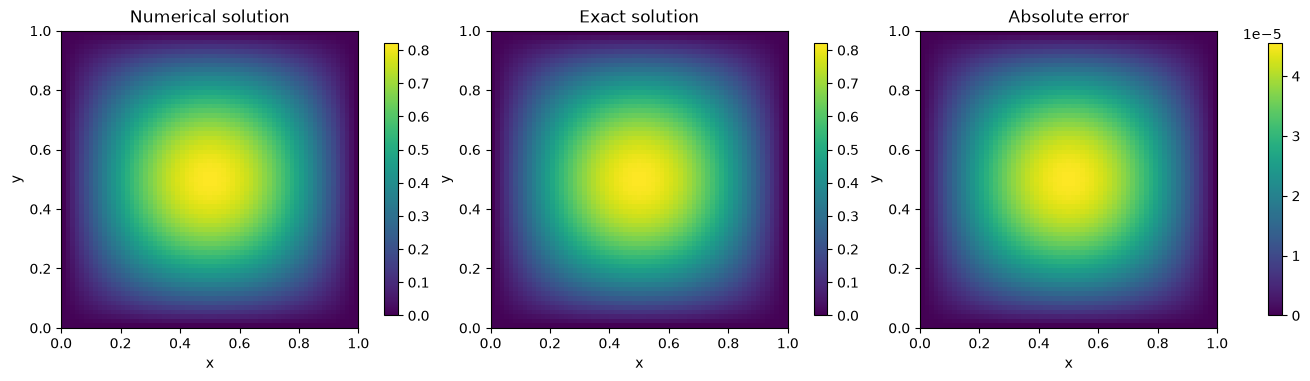

In [160]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
fields = [u_num, u_exact, jnp.abs(err)]
titles = ["Numerical solution", "Exact solution", "Absolute error"]
for ax, field, title in zip(axes, fields, titles):
    im = ax.imshow(
        np.asarray(field).T, origin="lower", extent=(0, Lx, 0, Ly),
        cmap="viridis", aspect="equal"
    )
    ax.set(xlabel="x", ylabel="y", title=title)
    fig.colorbar(im, ax=ax, shrink=0.78)
plt.show()

理论上，中心差分的空间误差为 $O(h^2)$，显式欧拉的时间误差为 $O(\Delta t)$，因此：

$$ E=O(h^2)+O(\Delta t). $$

本实验令 $\Delta t\propto h^2$，则预计总体误差近似满足：

$$\boxed{E\propto h^2}. $$

所以把网格步长减半，误差理论上会接近原来的 $1/4$。我们用四种网格测试它。

In [161]:
def run_case(n, nu=0.1, t_end=0.1, safety=0.8):
    h = 1.0 / (n - 1)
    grid = jnp.linspace(0.0, 1.0, n)
    xx, yy = jnp.meshgrid(grid, grid, indexing="ij")
    initial = jnp.sin(jnp.pi * xx) * jnp.sin(jnp.pi * yy)

    dt_max = h**2 / (4.0 * nu)
    steps = int(np.ceil(t_end / (safety * dt_max)))
    actual_dt = t_end / steps
    numerical = evolve(initial, actual_dt, h, h, nu, steps)
    exact = initial * jnp.exp(-2 * jnp.pi**2 * nu * t_end)
    e = float(jnp.max(jnp.abs(numerical - exact)))
    return h, e, steps

sizes = [17, 33, 65, 129]
results = [run_case(n) for n in sizes]
h_values = np.array([r[0] for r in results])
errors = np.array([r[1] for r in results])

for n, (h, error, steps) in zip(sizes, results):
    print(f"N={n:3d} | h={h:.6f} | steps={steps:4d} | max_error={error:.6e}")

slope = np.polyfit(np.log(h_values), np.log(errors), 1)[0]
print(f"\n拟合的收敛阶数 p ≈ {slope:.3f}")

N= 17 | h=0.062500 | steps=  13 | max_error=7.145321e-04
N= 33 | h=0.031250 | steps=  52 | max_error=1.777029e-04
N= 65 | h=0.015625 | steps= 205 | max_error=4.549410e-05
N=129 | h=0.007812 | steps= 820 | max_error=1.136975e-05

拟合的收敛阶数 p ≈ 1.989


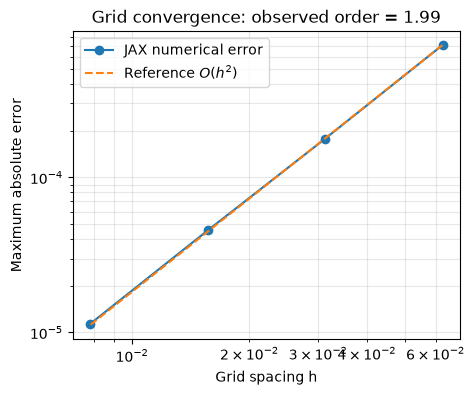

In [162]:
plt.figure(figsize=(5, 4))
plt.loglog(h_values, errors, "o-", label="JAX numerical error")
plt.loglog(h_values, errors[0] * (h_values / h_values[0])**2,
           "--", label=r"Reference $O(h^2)$")
plt.xlabel("Grid spacing h")
plt.ylabel("Maximum absolute error")
plt.title(f"Grid convergence: observed order = {slope:.2f}")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [171]:
test1 = jnp.array([[1, 2, 3, 4],
                   [5, 6, 7, 8],
                   [9, 10, 11, 12],
                   [13, 14, 15, 16]])
test1_center = test1[1:-1, 1:-1]
test1_x_left = test1[:-2, 1:-1]
test1_x_right = test1[2:, 1:-1]
test1_y_left = test1[1:-1, :-2]
test1_y_right = test1[1:-1, 2:]
print("Original:\n", np.asarray(test1))
print("Center:\n", np.asarray(test1_center))
print("Left neighbor (x direction):\n", np.asarray(test1_x_left))
print("Right neighbor (x direction):\n", np.asarray(test1_x_right))
print("Left neighbor (y direction):\n", np.asarray(test1_y_left))
print("Right neighbor (y direction):\n", np.asarray(test1_y_right))

Original:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]
Center:
 [[ 6  7]
 [10 11]]
Left neighbor (x direction):
 [[2 3]
 [6 7]]
Right neighbor (x direction):
 [[10 11]
 [14 15]]
Left neighbor (y direction):
 [[ 5  6]
 [ 9 10]]
Right neighbor (y direction):
 [[ 7  8]
 [11 12]]


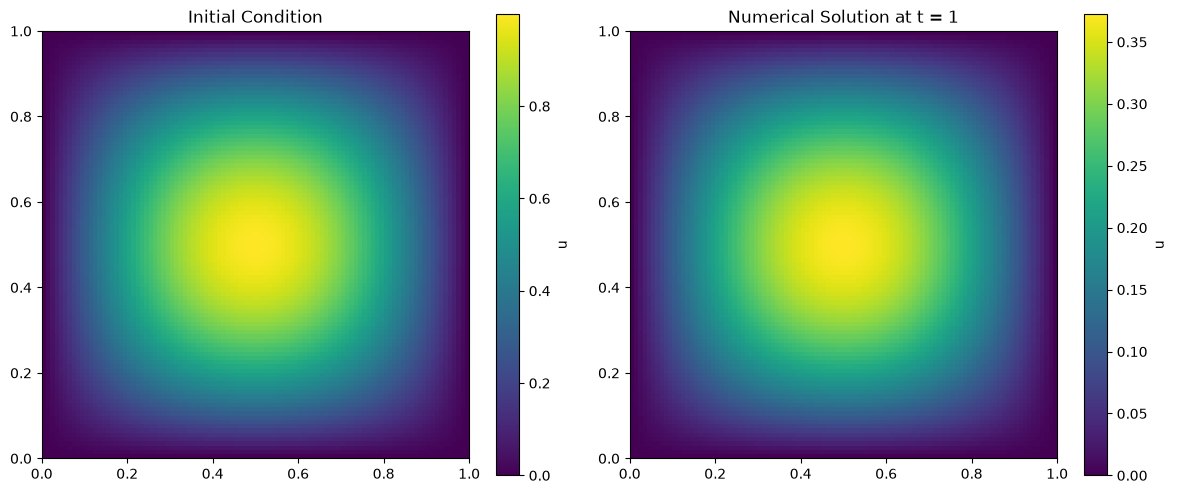

In [170]:
#连续，自行编写全部模块
#1、导入包
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import sys
import time
import numpy as np

#设置参数
Nx=100
Ny=100
Lx=1.0
Ly=1.0
dx=Lx/(Nx-1)
dy=Ly/(Ny-1)
t_end=1
miu=0.05

#定义拉普拉斯算子
def laplacian(u, dx, dy):
    center = u[1:-1, 1:-1]
    d2x = (u[2:, 1:-1] - 2.0 * center + u[:-2, 1:-1]) / dx**2
    d2y = (u[1:-1, 2:] - 2.0 * center + u[1:-1, :-2]) / dy**2
    return jnp.zeros_like(u).at[1:-1, 1:-1].set(d2x + d2y)

#定义时间步推进
def step(u, dt, dx, dy, nu):
    u_next = u + nu * dt * laplacian(u, dx, dy)
    return (
        u_next.at[0, :].set(0.0)
              .at[-1, :].set(0.0)
              .at[:, 0].set(0.0)
              .at[:, -1].set(0.0)
    )

#定义演化函数
@jax.jit
def evolve(u0, dt, dx, dy, nu, nsteps):
    return jax.lax.fori_loop(
        0,
        nsteps,
        lambda i, u: step(u, dt, dx, dy, nu),
        u0
    )

#设置网格和初始条件
x = jnp.linspace(0.0, Lx, Nx)
y = jnp.linspace(0.0, Ly, Ny)
X, Y = jnp.meshgrid(x, y, indexing="ij")
u0 = jnp.sin(jnp.pi * X) * jnp.sin(jnp.pi * Y)


#计算时间步长和步数
dt_max = 0.5 / (miu * (1.0 / dx**2 + 1.0 / dy**2))
safety = 0.8
nsteps = int(np.ceil(t_end / (safety * dt_max)))
dt = t_end / nsteps

#进行计算
u_num = evolve(u0, dt, dx, dy, miu, nsteps)

#绘制初态和结果：
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.asarray(u0).T, origin="lower", extent=(0, Lx, 0, Ly), cmap="viridis")
plt.title("Initial Condition")
plt.colorbar(label="u")
plt.subplot(1, 2, 2)
plt.imshow(np.asarray(u_num).T, origin="lower", extent=(0, Lx, 0, Ly), cmap="viridis")
plt.title(f"Numerical Solution at t = {t_end}")
plt.colorbar(label="u")
plt.tight_layout()
plt.show()  




